In [8]:
%pylab inline
import gc
import os
import smatch
import numpy as np

import pandas as pd
import matplotlib
import matplotlib.lines as mlines

import astropy.io.fits as pyfits
import matplotlib.pyplot as plt
from astropy.table import Table,join,vstack

import sim_analysis_utilities as utilities
import plot_utilities as pltUtil

version =   's19-Hironao-2'
obsDir  =   'wrkDir/database/%s/fields/' %version
assert os.path.isdir(obsDir)

Populating the interactive namespace from numpy and matplotlib


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/IPython/core/magics/pylab.py:160: UserWarning: pylab import has clobbered these variables: ['vstack']
`%matplotlib` prevents importing * from pylab and numpy
  "\n`%matplotlib` prevents importing * from pylab and numpy"


# Observed HSC data

+ Prepare small catalog

+ Plot 1D histograms
    + variance,fwhm
    
    + snr,res,$|e|$,mag
    

+ Plot 2D histograms
    

## prepare small Catalog

In [26]:
# Get field tract information
if False:
    tractInfo={}
    for fieldname in utilities.field_names:
        obsFname=   os.path.join(obsDir,'%s.fits' %(fieldname))
        assert os.path.isfile(obsFname)
        tt=np.unique(pyfits.getdata(obsFname)['tract'])
        fieldsCol.extend([fieldname]*len(tt))
        tractsCol.extend(tt)
    tab=Table(data=(fieldsCol,tractsCol),names=('field','tract'))
    tab.write('wrkDir/fieldTractInfoS19.csv')

In [5]:
# make small catalog for AEGIS
if True:
    fieldname='AEGIS'
    obsFname=   os.path.join(obsDir,'%s.fits' %(fieldname))
    a=utilities.make_smallcat_obs(obsFname,fieldname)

/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/sim_analysis_utilities.py:1333: RuntimeWarning: invalid value encountered in power
  size = (gal_mxx * gal_myy - gal_mxy**2)**(0.25)
/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/sim_analysis_utilities.py:1194: RuntimeWarning: invalid value encountered in greater_equal
  g_mask  =   (g_snr >= min_multiband_snr_data) & (~np.isnan(g_snr) & (gcountinputs >= 2))
/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/sim_analysis_utilities.py:1195: RuntimeWarning: invalid value encountered in greater_equal
  r_mask  =   (r_snr >= min_multiband_snr_data) & (~np.isnan(r_snr) & (rcountinputs >= 2))
/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/sim_analysis_utilities.py:1196: RuntimeWarning: invalid value encountered in greater_equal
  z_mask  =   (z_snr >= min_multiband_snr_data) & (~np.isnan(z_snr) & (zcountinputs >= 2))
/work/xiangchong.li/superonionGW/code/FPFS_Private/FP

In [7]:
if False:
    # make small catalog (excluding AEGIS)
    allObs  =   []
    for fieldname in utilities.field_names:
        obsFname=   os.path.join(obsDir,'%s.fits' %(fieldname))
        allObs.append(utilities.make_smallcat_obs(obsFname,fieldname))
        n = gc.collect()
        print("Number of unreachable objects collected by GC:", n)
        print("Uncollectable garbage:", gc.garbage)
    allObs  =   vstack(allObs)
    allObs=allObs[allObs['magA10']<25.5]
    allObs.write('./wrkDir/database/smallcat-wl-s19-2.fits',overwrite=True)
else:
    allObs=pyfits.getdata('./wrkDir/database/smallcat-wl-s19-2.fits')

/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/sim_analysis_utilities.py:1179: RuntimeWarning: divide by zero encountered in true_divide
  z_snr   =   (2.5/np.log(10.0)) / catalog['forced_z_%s'%pendN]


Number of unreachable objects collected by GC: 8
Uncollectable garbage: []
Number of unreachable objects collected by GC: 0
Uncollectable garbage: []
Number of unreachable objects collected by GC: 0
Uncollectable garbage: []
Number of unreachable objects collected by GC: 0
Uncollectable garbage: []
Number of unreachable objects collected by GC: 0
Uncollectable garbage: []
Number of unreachable objects collected by GC: 0
Uncollectable garbage: []


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/astropy/table/column.py:991: RuntimeWarning: invalid value encountered in less
  result = getattr(super(), op)(other)


## 1-D histograms
### FWHM, noivar

In [9]:
nbin1=20
fwhm_bin   =   np.linspace(0.3,0.9,nbin1)
fwhm_bin_0 =   fwhm_bin[:-1]
fwhm_bin_1 =   fwhm_bin[1:]
gridPsf    =   (fwhm_bin_0+fwhm_bin_1)/2.
var_bin    =   np.linspace(0.001,0.01,nbin1)
var_bin_0  =   var_bin[:-1]
var_bin_1  =   var_bin[1:]
gridNoi    =   (var_bin_0+var_bin_1)/2.
fwhms   =   allObs['fwhm']
varNois =   allObs['noivar']

2392090
1946310
2624108
6973322
4260213
8212010
9428758
7097222
10354839
3192256
2088188
3556105
7176210
4896252
8159188
3373173
2365108
3753529
32535809
22653293
36659779


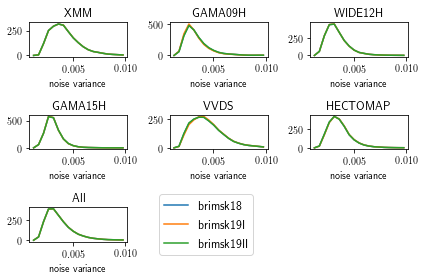

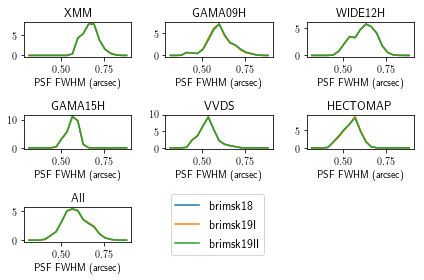

In [10]:
figN=   plt.figure()
figP=   plt.figure()

for ii,fieldKey in enumerate(utilities.field_keys):
    fieldname   =   utilities.field_keys[fieldKey]
    axN =   figN.add_subplot(3,3,ii+1)
    axN.set_xlabel('noise variance')
    axN.set_title(fieldname)
    axP =   figP.add_subplot(3,3,ii+1)
    axP.set_xlabel('PSF FWHM (arcsec)')
    axP.set_title(fieldname)

    fieldname   =   utilities.field_keys[fieldKey]
    mask=(allObs['fieldname']==fieldname)
    for bmname in ['brimsk18','brimsk19I','brimsk19II']:
        mask1=(mask&(~allObs[bmname]))
        print(np.sum(mask1))
        histNoi =   np.histogram(varNois[mask1],bins=var_bin,density=True)[0]
        histPsf =   np.histogram(fwhms[mask1],bins=fwhm_bin,density=True)[0]
        axN.plot(gridNoi,histNoi,label=bmname)
        axP.plot(gridPsf,histPsf,label=bmname)
        
axN =   figN.add_subplot(3,3,7)
axN.set_xlabel('noise variance')
axN.set_title('All')
axP =   figP.add_subplot(3,3,7)
axP.set_xlabel('PSF FWHM (arcsec)')
axP.set_title('All')

for bmname in ['brimsk18','brimsk19I','brimsk19II']:
    mask1=(~allObs[bmname])
    print(np.sum(mask1))
    histNoi =   np.histogram(varNois[mask1],bins=var_bin,density=True)[0]
    histPsf =   np.histogram(fwhms[mask1],bins=fwhm_bin,density=True)[0]
    axN.plot(gridNoi,histNoi,label=bmname)
    axP.plot(gridPsf,histPsf,label=bmname)

figN.tight_layout()
figP.tight_layout()

axN.legend(loc='center', bbox_to_anchor=(1.8, 0.5),fontsize=12)
axP.legend(loc='center', bbox_to_anchor=(1.8, 0.5),fontsize=12)

### snr, res, |e|, mag

In [11]:
nbin2      =   60
snr_bin    =   np.linspace(0.,80.,nbin2)
snr_bin_0  =   snr_bin[:-1]
snr_bin_1  =   snr_bin[1:]
snrGrid    =   (snr_bin_0+snr_bin_1)/2.
resolution_bin=np.linspace(0.1,1.,nbin2)
resolution_bin_0  =   resolution_bin[:-1]
resolution_bin_1  =   resolution_bin[1:]
resGrid    =   (resolution_bin_0+resolution_bin_1)/2.
mag_bin    =   np.linspace(22.,25.2,nbin2)
mag_bin_0  =   mag_bin[:-1]
mag_bin_1  =   mag_bin[1:]
magGrid    =   (mag_bin_0+mag_bin_1)/2.
absE_bin   =   np.linspace(0.,2.,nbin2)
absE_bin_0 =   absE_bin[:-1]
absE_bin_1 =   absE_bin[1:]
absEGrid   =   (absE_bin_0+absE_bin_1)/2.
res   =   allObs['res']
snr   =   allObs['snr']
mag   =   allObs['mag']
absE  =   allObs['absE']

2392090
1946310
2624108
6973322
4260213
8212010
9428758
7097222
10354839
3192256
2088188
3556105
7176210
4896252
8159188
3373173
2365108
3753529
32535809
22653293
36659779


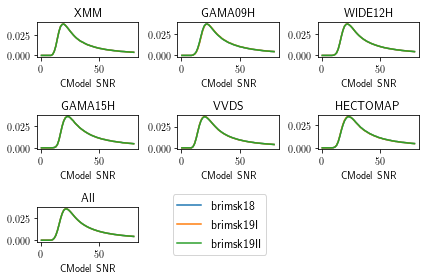

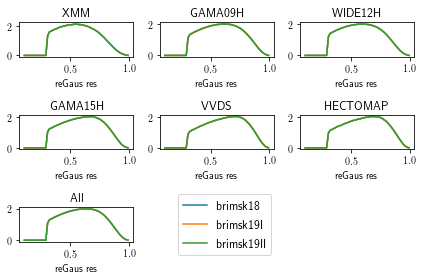

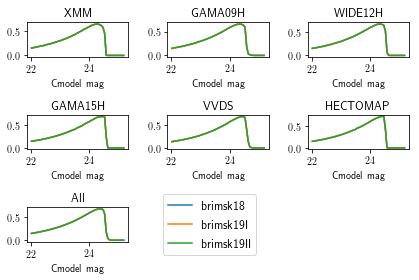

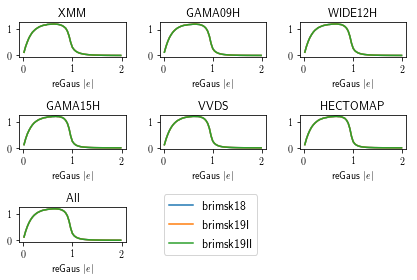

In [12]:
figS=   plt.figure()
figR=   plt.figure()
figM=   plt.figure()
figA=   plt.figure()

for ii,fieldKey in enumerate(utilities.field_keys):
    fieldname   =   utilities.field_keys[fieldKey]
    axS =   figS.add_subplot(3,3,ii+1)
    axS.set_xlabel('CModel SNR')
    axS.set_title(fieldname)
    axR =   figR.add_subplot(3,3,ii+1)
    axR.set_xlabel('reGaus res')
    axR.set_title(fieldname)
    axM =   figM.add_subplot(3,3,ii+1)
    axM.set_xlabel('Cmodel mag')
    axM.set_title(fieldname)
    axA =   figA.add_subplot(3,3,ii+1)
    axA.set_xlabel(r'reGaus $|e|$')
    axA.set_title(fieldname)

    fieldname   =   utilities.field_keys[fieldKey]
    mask=(allObs['fieldname']==fieldname)
    for bmname in ['brimsk18','brimsk19I','brimsk19II']:
        mask1=(mask&(~allObs[bmname]))
        print(np.sum(mask1))
        histSNR =   np.histogram(snr[mask1],bins=snr_bin,density=True)[0]
        axS.plot(snrGrid,histSNR,label=bmname)
        histRes =   np.histogram(res[mask1],bins=resolution_bin,density=True)[0]
        axR.plot(resGrid,histRes,label=bmname)
        histMag =   np.histogram(mag[mask1],bins=mag_bin,density=True)[0]
        axM.plot(magGrid,histMag,label=bmname)
        histAbsE =   np.histogram(absE[mask1],bins=absE_bin,density=True)[0]
        axA.plot(absEGrid,histAbsE,label=bmname)
        
axS =   figS.add_subplot(3,3,7)
axS.set_xlabel('CModel SNR')
axS.set_title('All')
axR =   figR.add_subplot(3,3,7)
axR.set_xlabel('reGaus res')
axR.set_title('All')
axM =   figM.add_subplot(3,3,7)
axM.set_xlabel('Cmodel mag')
axM.set_title('All')
axA =   figA.add_subplot(3,3,7)
axA.set_xlabel(r'reGaus $|e|$')
axA.set_title('All')
for bmname in ['brimsk18','brimsk19I','brimsk19II']:
    mask1=(~allObs[bmname])
    print(np.sum(mask1))
    histSNR =   np.histogram(snr[mask1],bins=snr_bin,density=True)[0]
    axS.plot(snrGrid,histSNR,label=bmname)
    histRes =   np.histogram(res[mask1],bins=resolution_bin,density=True)[0]
    axR.plot(resGrid,histRes,label=bmname)
    histMag =   np.histogram(mag[mask1],bins=mag_bin,density=True)[0]
    axM.plot(magGrid,histMag,label=bmname)
    histAbsE =   np.histogram(absE[mask1],bins=absE_bin,density=True)[0]
    axA.plot(absEGrid,histAbsE,label=bmname)

figS.tight_layout()
figR.tight_layout()
figM.tight_layout()
figA.tight_layout()

axS.legend(loc='center', bbox_to_anchor=(1.8, 0.5),fontsize=12)
axR.legend(loc='center', bbox_to_anchor=(1.8, 0.5),fontsize=12)
axM.legend(loc='center', bbox_to_anchor=(1.8, 0.5),fontsize=12)
axA.legend(loc='center', bbox_to_anchor=(1.8, 0.5),fontsize=12)

## 2-D histograms

32535809
68.26666666666667
22653293
68.26666666666667
36659779
68.26666666666667
32535809
10.24
22653293
10.24
36659779
10.239999999999998
32535809
51.2
22653293
51.199999999999996
36659779
51.2


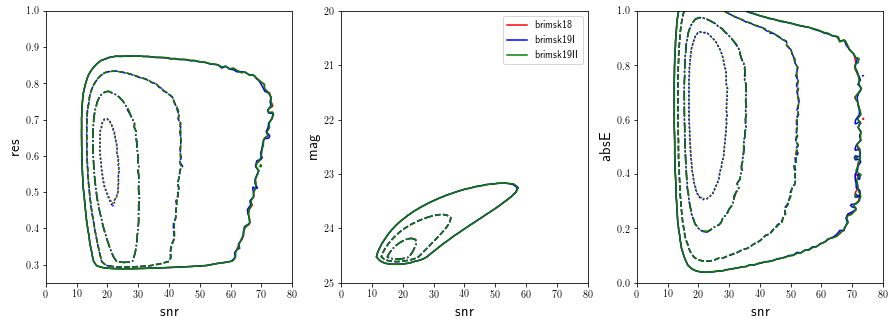

In [13]:
pergroup=3
ngridH=64
colns1=['snr', 'snr','snr']
colns2=['res', 'mag','absE']
clist=['red','blue','green']
mlist=['brimsk18','brimsk19I','brimsk19II']
linelist=[]
for im in range(3):
    m_line = mlines.Line2D([], [], color=clist[im], ls='-', label=mlist[im])
    linelist.append(m_line)


lslist=['solid', 'dashed', 'dashdot', 'dotted']
lvlist=[[0.01, 0.025, 0.05, 0.075],[0.01, 0.025, 0.05, 0.075],[0.0065, 0.012, 0.025, 0.035]]

fig     =   plt.figure(figsize=(5*pergroup, 5))
axes    =   []
for j in range(pergroup):
    axes.append(fig.add_subplot(1,pergroup,j+1))


for i in range(pergroup):
    xMin,xMax   =   pltUtil.obsRanges[colns1[i]]
    yMin,yMax   =   pltUtil.obsRanges[colns2[i]]
    drange  =   [[xMin,xMax],[yMin,yMax]]
    dextent =   [xMin,xMax,yMin,yMax]

    ax      =   axes[i]
    if 'mag' in colns1[i]:
        ax.invert_xaxis()
    if 'mag' in colns2[i]:
        ax.invert_yaxis()

    ax.set_xlabel(colns1[i].replace('_',' '),fontsize=15)
    ax.set_ylabel(colns2[i].replace('_',' '),fontsize=15)
        
    x       =   allObs[colns1[i]]
    y       =   allObs[colns2[i]]
    
    for im,bmname in enumerate(mlist):
        mask1=(~allObs[bmname])
        counts  =   np.histogram2d(x[mask1],y[mask1],ngridH,range=drange,density=True)[0]
        print(np.sum(mask1))
        print(np.sum(counts))
        ax.contour(counts.T,extent=dextent,colors=clist[im],levels=lvlist[i],linestyles=lslist)
axes[1].legend(handles=linelist)


14006486
14006486
14006486


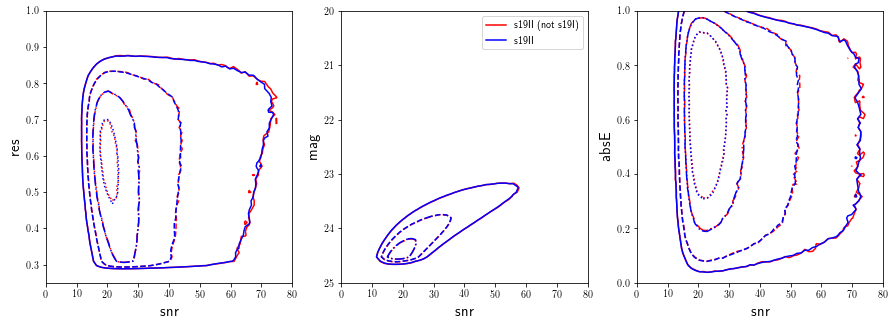

In [17]:
ngridH=64
colns1=['snr', 'snr','snr']
colns2=['res', 'mag','absE']
linelist=[]
m_line = mlines.Line2D([], [], color='red', ls='-', label='s19II (not s19I)')
linelist.append(m_line)
m_line = mlines.Line2D([], [], color='blue', ls='-', label='s19II')
linelist.append(m_line)


lslist=['solid', 'dashed', 'dashdot', 'dotted']
lvlist=[[0.01, 0.025, 0.05, 0.075],[0.01, 0.025, 0.05, 0.075],[0.0065, 0.012, 0.025, 0.035]]

fig     =   plt.figure(figsize=(5*pergroup, 5))
axes    =   []
for j in range(pergroup):
    axes.append(fig.add_subplot(1,pergroup,j+1))


for i in range(pergroup):
    xMin,xMax   =   pltUtil.obsRanges[colns1[i]]
    yMin,yMax   =   pltUtil.obsRanges[colns2[i]]
    drange  =   [[xMin,xMax],[yMin,yMax]]
    dextent =   [xMin,xMax,yMin,yMax]

    ax      =   axes[i]
    if 'mag' in colns1[i]:
        ax.invert_xaxis()
    if 'mag' in colns2[i]:
        ax.invert_yaxis()

    ax.set_xlabel(colns1[i].replace('_',' '),fontsize=15)
    ax.set_ylabel(colns2[i].replace('_',' '),fontsize=15)
        
    x       =   allObs[colns1[i]]
    y       =   allObs[colns2[i]]
    
    mask1=(allObs['brimsk19I'])
    counts  =   np.histogram2d(x[mask1],y[mask1],ngridH,range=drange,density=True)[0]
    print(np.sum(mask1))
    ax.contour(counts.T,extent=dextent,colors='red',levels=lvlist[i],linestyles=lslist)
    counts  =   np.histogram2d(x,y,ngridH,range=drange,density=True)[0]
    ax.contour(counts.T,extent=dextent,colors='blue',levels=lvlist[i],linestyles=lslist)
axes[1].legend(handles=linelist)

36659779
38279802
36659779
38279802
36659779
38279802


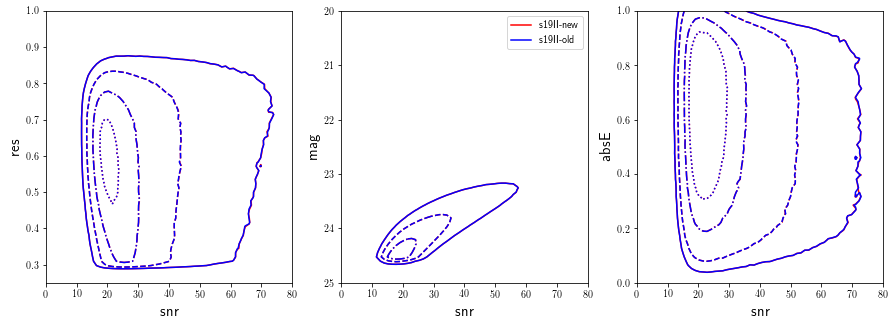

In [19]:
ngridH=64
colns1=['snr', 'snr','snr']
colns2=['res', 'mag','absE']
linelist=[]
m_line = mlines.Line2D([], [], color='red', ls='-', label='s19II-new')
linelist.append(m_line)
m_line = mlines.Line2D([], [], color='blue', ls='-', label='s19II-old')
linelist.append(m_line)


lslist=['solid', 'dashed', 'dashdot', 'dotted']
lvlist=[[0.01, 0.025, 0.05, 0.075],[0.01, 0.025, 0.05, 0.075],[0.0065, 0.012, 0.025, 0.035]]

fig     =   plt.figure(figsize=(5*pergroup, 5))
axes    =   []
for j in range(pergroup):
    axes.append(fig.add_subplot(1,pergroup,j+1))


allObs2=pyfits.getdata('./wrkDir/database/smallcat-wl-s19.fits')
for i in range(pergroup):
    xMin,xMax   =   pltUtil.obsRanges[colns1[i]]
    yMin,yMax   =   pltUtil.obsRanges[colns2[i]]
    drange  =   [[xMin,xMax],[yMin,yMax]]
    dextent =   [xMin,xMax,yMin,yMax]

    ax      =   axes[i]
    if 'mag' in colns1[i]:
        ax.invert_xaxis()
    if 'mag' in colns2[i]:
        ax.invert_yaxis()

    ax.set_xlabel(colns1[i].replace('_',' '),fontsize=15)
    ax.set_ylabel(colns2[i].replace('_',' '),fontsize=15)
        
    print(len(allObs))
    print(len(allObs2))
    x       =   allObs[colns1[i]]
    y       =   allObs[colns2[i]]
    counts  =   np.histogram2d(x,y,ngridH,range=drange,density=True)[0]
    ax.contour(counts.T,extent=dextent,colors='red',levels=lvlist[i],linestyles=lslist)
    x2       =   allObs2[colns1[i]]
    y2       =   allObs2[colns2[i]]
    counts2  =   np.histogram2d(x2,y2,ngridH,range=drange,density=True)[0]
    ax.contour(counts2.T,extent=dextent,colors='blue',levels=lvlist[i],linestyles=lslist)
axes[1].legend(handles=linelist)